# Лабораторна робота №4. Регресійні моделі: глибоке дослідження

**Датасет:** Car Price Prediction Multiple Linear Regression  
https://www.kaggle.com/datasets/hellbuoy/car-price-prediction?select=CarPrice_Assignment.csv

**Мета роботи:** виконати підготовку даних, побудувати та порівняти регресійні моделі для прогнозування ціни автомобіля, оцінити їх якість і проаналізувати отримані результати.

> У шаблоні наведено лише умови завдань. Реалізацію необхідно виконати самостійно у порожніх комірках.


## 1. Завантаження та первинний аналіз даних

Завантажити датасет та виконати його первинний огляд:
- визначити кількість об'єктів і ознак;
- переглянути назви стовпців;
- визначити типи даних;
- визначити цільову змінну;
- вивести основні статистичні характеристики даних.


In [1]:
import io
import pandas as pd
from google.colab import files

uploaded = files.upload()
file_name = next(iter(uploaded))

if file_name.endswith('.csv'):
  df = pd.read_csv(io.BytesIO(uploaded[file_name]))
elif file_name.endswith(('.xlsx', '.xls')):
  df = pd.read_excel(io.BytesIO(uploaded[file_name]))
elif file_name.endswith('.json'):
  df = pd.read_json(io.BytesIO(uploaded[file_name]))
else:
  df = pd.read_csv(io.BytesIO(uploaded[file_name]))

print("Кількість об'єктів та ознак:", df.shape)
print("\nНазви стовпців:", list(df.columns))
print("\nТипи даних:\n", df.dtypes)
print("\nПерші 5 рядків:\n", df.head())
print("\nОсновні статистики:\n", df.describe(include='all'))

Saving CarPrice_Assignment.csv to CarPrice_Assignment.csv
Кількість об'єктів та ознак: (205, 26)

Назви стовпців: ['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']

Типи даних:
 car_ID                int64
symboling             int64
CarName              object
fueltype             object
aspiration           object
doornumber           object
carbody              object
drivewheel           object
enginelocation       object
wheelbase           float64
carlength           float64
carwidth            float64
carheight           float64
curbweight            int64
enginetype           object
cylindernumber       object
enginesize            int64
fuelsystem           object
boreratio           flo

## 2. Перевірка якості даних

Перевірити:
- наявність пропущених значень;
- наявність повних дублікатів;
- кількість унікальних значень в ознаках.

Під час аналізу врахувати, що `car_ID` є унікальним ідентифікатором автомобіля і сам по собі не повинен використовуватися для визначення дублікатів за змістовими характеристиками.


In [2]:
print("Пропущені значення:\n", df.isnull().sum())
print("\nПовні дублікати (усі стовпці):", df.duplicated().sum())

feature_cols = [col for col in df.columns if col != "car_ID"]
print(
    "\nДублікати за ознаками (без car_ID):",
    df.duplicated(subset=feature_cols).sum(),
)
print("\nКількість унікальних значень:\n", df.nunique())

Пропущені значення:
 car_ID              0
symboling           0
CarName             0
fueltype            0
aspiration          0
doornumber          0
carbody             0
drivewheel          0
enginelocation      0
wheelbase           0
carlength           0
carwidth            0
carheight           0
curbweight          0
enginetype          0
cylindernumber      0
enginesize          0
fuelsystem          0
boreratio           0
stroke              0
compressionratio    0
horsepower          0
peakrpm             0
citympg             0
highwaympg          0
price               0
dtype: int64

Повні дублікати (усі стовпці): 0

Дублікати за ознаками (без car_ID): 0

Кількість унікальних значень:
 car_ID              205
symboling             6
CarName             147
fueltype              2
aspiration            2
doornumber            2
carbody               5
drivewheel            3
enginelocation        2
wheelbase            53
carlength            75
carwidth             44
c

## 3. Робота з car_ID

Зберегти `car_ID` окремо для подальшої ідентифікації автомобілів у результатах прогнозування.  
Не використовувати `car_ID` як ознаку під час навчання моделей.


In [3]:
car_ids = df['car_ID'].copy()
X = df.drop(columns=['car_ID', 'price'])
y = df['price']

## 4. Дослідження розподілів числових ознак

Дослідити розподіли числових ознак:
- побудувати відповідні графіки;
- обчислити коефіцієнти асиметрії;
- визначити ознаки з найбільш вираженою асиметрією;
- коротко прокоментувати отримані результати.


Коефіцієнти асиметрії (за спаданням модуля):
 compressionratio    2.610862
enginesize          1.947655
horsepower          1.405310
wheelbase           1.050214
carwidth            0.904003
stroke             -0.689705
curbweight          0.681398
citympg             0.663704
highwaympg          0.539997
symboling           0.211072
carlength           0.155954
peakrpm             0.075159
carheight           0.063123
boreratio           0.020156
dtype: float64


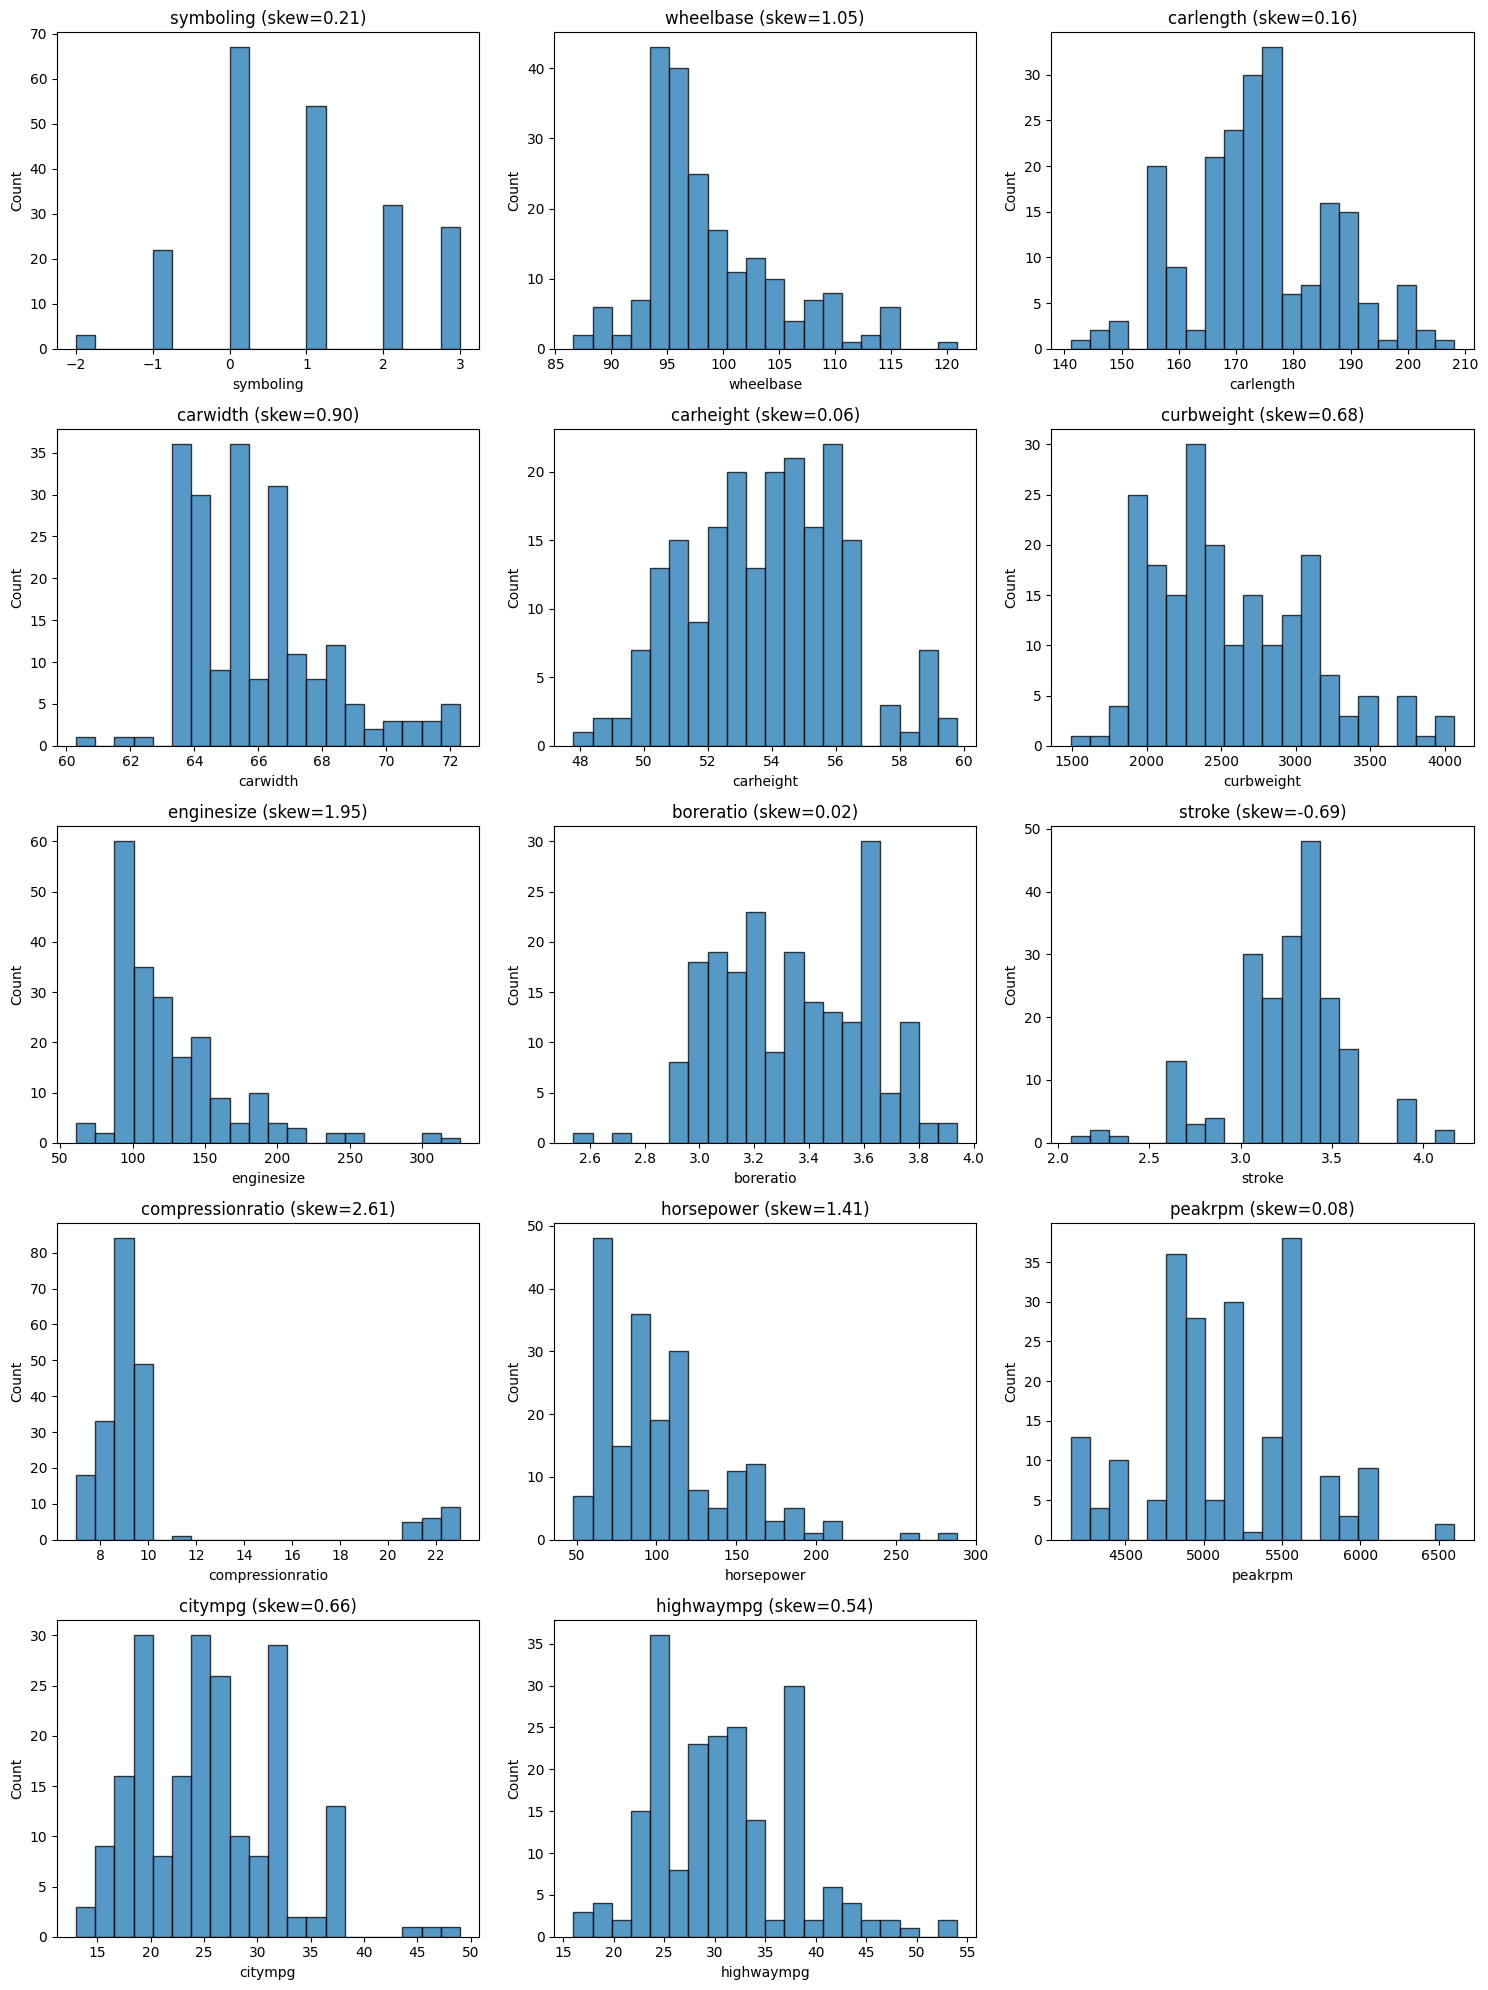

In [4]:
import math
import matplotlib.pyplot as plt
import numpy as np

num_cols = X.select_dtypes(include=[np.number]).columns.tolist()

skew_values = X[num_cols].skew().sort_values(key=lambda s: s.abs(), ascending=False)
print("Коефіцієнти асиметрії (за спаданням модуля):\n", skew_values)

n_cols = 3
n_rows = math.ceil(len(num_cols) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
axes = axes.flatten()

for i, col in enumerate(num_cols):
  axes[i].hist(X[col].dropna(), bins=20, edgecolor="black", alpha=0.75)
  axes[i].set_title(f"{col} (skew={X[col].skew():.2f})")
  axes[i].set_xlabel(col)
  axes[i].set_ylabel("Count")

for j in range(len(num_cols), len(axes)):
  fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

## 5. Формування train/test вибірок

Відокремити цільову змінну `price` від ознак та розділити дані на:
- навчальну вибірку — 80%;
- тестову вибірку — 20%.

Забезпечити відтворюваність поділу.  
Окремо зберегти `car_ID` для об'єктів, які потрапили до train і test.

**Важливо:** усі подальші параметри передобробки даних визначати тільки за навчальною вибіркою.


In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test, car_id_train, car_id_test = train_test_split(
    X, y, car_ids, test_size=0.2, random_state=42
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("car_id_train len:", len(car_id_train))
print("car_id_test len:", len(car_id_test))

X_train shape: (164, 24)
X_test shape: (41, 24)
car_id_train len: 164
car_id_test len: 41


## 6. Аналіз та обробка викидів

Для неперервних числових ознак навчальної вибірки:
- визначити потенційні викиди методом IQR;
- вивести кількість потенційних викидів для кожної ознаки;
- обґрунтувати спосіб їх обробки.

Для невеликого набору даних не видаляти автоматично всі рядки з викидами. Використати обмеження крайніх значень межами, визначеними за навчальною вибіркою.

Цільову змінну `price` не використовувати для визначення меж викидів.  
До тестової вибірки застосувати ті самі межі, які були отримані за train.


In [6]:
import numpy as np

cont_cols = [
    col
    for col in X_train.select_dtypes(include=[np.number]).columns
    if X_train[col].nunique() > 10
]

bounds = {}
outlier_counts = {}

for col in cont_cols:
  q1 = X_train[col].quantile(0.25)
  q3 = X_train[col].quantile(0.75)
  iqr = q3 - q1
  lower = q1 - 1.5 * iqr
  upper = q3 + 1.5 * iqr
  bounds[col] = (lower, upper)
  outlier_counts[col] = int(
      ((X_train[col] < lower) | (X_train[col] > upper)).sum()
  )

print("Кількість потенційних викидів у X_train за методом IQR:")
for col, cnt in outlier_counts.items():
  print(f"{col}: {cnt}")

for col, (lower, upper) in bounds.items():
  X_train[col] = X_train[col].clip(lower=lower, upper=upper)
  X_test[col] = X_test[col].clip(lower=lower, upper=upper)

Кількість потенційних викидів у X_train за методом IQR:
wheelbase: 6
carlength: 0
carwidth: 10
carheight: 0
curbweight: 0
enginesize: 7
boreratio: 1
stroke: 16
compressionratio: 20
horsepower: 7
peakrpm: 2
citympg: 0
highwaympg: 1


## 7. Аналіз кореляцій та відбір ознак

За навчальною вибіркою:
- побудувати матрицю кореляцій числових ознак;
- знайти пари ознак із сильною кореляцією, для яких `|r| > 0.85`;
- для кожної такої пари залишити одну ознаку;
- під час вибору врахувати силу зв'язку кожної ознаки з цільовою змінною `price`;
- вивести список сильно корельованих пар та перелік ознак, які видаляються.

Із тестової вибірки видалити ті самі ознаки.  
Не використовувати тестову вибірку для прийняття рішення про відбір ознак.


In [7]:
import numpy as np

num_train_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()
corr_matrix = X_train[num_train_cols].corr()
target_corr = X_train[num_train_cols].corrwith(y_train).abs()

high_corr_pairs = []
to_drop = set()

for i in range(len(num_train_cols)):
  for j in range(i + 1, len(num_train_cols)):
    c1, c2 = num_train_cols[i], num_train_cols[j]
    r = corr_matrix.loc[c1, c2]
    if abs(r) > 0.85:
      high_corr_pairs.append((c1, c2, float(r)))
      if target_corr[c1] >= target_corr[c2]:
        to_drop.add(c2)
      else:
        to_drop.add(c1)

to_drop_sorted = sorted(to_drop)

print("Пари з |r| > 0.85:")
for c1, c2, r in high_corr_pairs:
  print(f"{c1} - {c2}: r = {r:.4f}")

print("\nОзнаки, які видаляються:", to_drop_sorted)

X_train = X_train.drop(columns=to_drop_sorted)
X_test = X_test.drop(columns=to_drop_sorted)

Пари з |r| > 0.85:
wheelbase - carlength: r = 0.8670
carlength - curbweight: r = 0.8660
carwidth - curbweight: r = 0.8580
citympg - highwaympg: r = 0.9636

Ознаки, які видаляються: ['carlength', 'carwidth', 'citympg', 'wheelbase']


## 8. Підготовка числових і категоріальних ознак

Розділити ознаки на:
- неперервні числові;
- дискретну числову ознаку `symboling`;
- категоріальні.

Для неперервних числових ознак виконати послідовно:
1. перетворення Yeo–Johnson для зменшення асиметрії;
2. масштабування за допомогою StandardScaler.

Для `symboling` виконати масштабування без Yeo–Johnson.

Категоріальні ознаки закодувати методом One-Hot Encoding. Передбачити коректну обробку категорій у test, яких не було у train.

Усі перетворення об'єднати в єдиний механізм передобробки даних, який навчається тільки на `X_train`.


In [8]:
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PowerTransformer, StandardScaler

cont_cols = [
    col
    for col in X_train.select_dtypes(include=[np.number]).columns
    if col != "symboling"
]
symboling_cols = ["symboling"] if "symboling" in X_train.columns else []
cat_cols = X_train.select_dtypes(exclude=[np.number]).columns.tolist()

cont_pipeline = Pipeline([
    ("yeo_johnson", PowerTransformer(method="yeo-johnson")),
    ("scaler", StandardScaler()),
])

symboling_pipeline = Pipeline([
    ("scaler", StandardScaler()),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("cont", cont_pipeline, cont_cols),
        ("symboling", symboling_pipeline, symboling_cols),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            cat_cols,
        ),
    ],
    remainder="drop",
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("X_train_processed shape:", X_train_processed.shape)
print("X_test_processed shape:", X_test_processed.shape)

X_train_processed shape: (164, 171)
X_test_processed shape: (41, 171)


## 9. Перевірка трансформації числових ознак

Перевірити результат трансформації неперервних числових ознак:
- застосувати до train ту саму послідовність перетворень, яка буде використана в моделях;
- повторно обчислити коефіцієнти асиметрії;
- порівняти їх із початковими значеннями;
- зробити короткий висновок щодо ефективності трансформації.


In [9]:
import pandas as pd

cont_transformed_train = preprocessor.named_transformers_["cont"].transform(
    X_train[cont_cols]
)
skew_before = X_train[cont_cols].skew()
skew_after = pd.Series(
    pd.DataFrame(cont_transformed_train, columns=cont_cols).skew(),
    index=cont_cols,
)

skew_comparison = pd.DataFrame({
    "skew_before": skew_before,
    "skew_after": skew_after,
    "abs_skew_before": skew_before.abs(),
    "abs_skew_after": skew_after.abs(),
}).sort_values(by="abs_skew_before", ascending=False)

print(skew_comparison)

                  skew_before  skew_after  abs_skew_before  abs_skew_after
enginesize           0.962394    0.044834         0.962394        0.044834
horsepower           0.850735    0.066280         0.850735        0.066280
curbweight           0.712433    0.049894         0.712433        0.049894
stroke              -0.397600    0.015846         0.397600        0.015846
highwaympg           0.243761   -0.012188         0.243761        0.012188
boreratio            0.062963   -0.005941         0.062963        0.005941
compressionratio     0.055710    0.004872         0.055710        0.004872
peakrpm              0.039773   -0.003589         0.039773        0.003589
carheight            0.028154   -0.005170         0.028154        0.005170


## 10. Побудова регресійних моделей

Побудувати та навчити такі моделі:
- Linear Regression;
- Ridge Regression;
- Lasso Regression;
- Random Forest Regressor;
- Gradient Boosting Regressor;
- Support Vector Regressor (SVR).

Для кожної моделі створити єдиний Pipeline, який містить:
1. попередню обробку ознак;
2. відповідну регресійну модель.

Використати однакову схему підготовки даних для коректного порівняння моделей.


In [10]:
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.pipeline import Pipeline
from sklearn.svm import SVR

regressors = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(random_state=42),
    'Lasso Regression': Lasso(random_state=42, max_iter=10000),
    'Random Forest Regressor': RandomForestRegressor(random_state=42),
    'Gradient Boosting Regressor': GradientBoostingRegressor(random_state=42),
    'SVR': SVR(),
}

pipelines = {}
for name, reg in regressors.items():
  pipe = Pipeline([('preprocessor', preprocessor), ('model', reg)])
  pipe.fit(X_train, y_train)
  pipelines[name] = pipe

print('Навчено моделей:', len(pipelines))

Навчено моделей: 6


## 11. Оцінювання якості моделей

Для кожної моделі:
- виконати навчання на тренувальній вибірці;
- отримати прогноз для тестової вибірки;
- обчислити метрики **R², MAE, MSE та MAPE**.

`MAPE` подати у відсотках.

Результати всіх моделей об'єднати в одну порівняльну таблицю та впорядкувати за значенням R² від найбільшого до найменшого.

Під час інтерпретації врахувати:
- R² — чим більше, тим краще;
- MAE, MSE, MAPE — чим менше, тим краще.


In [11]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error,
    mean_squared_error,
    r2_score,
)

metrics_rows = []

for name, pipe in pipelines.items():
  pipe.fit(X_train, y_train)
  y_pred = pipe.predict(X_test)
  metrics_rows.append({
      "Model": name,
      "R2": r2_score(y_test, y_pred),
      "MAE": mean_absolute_error(y_test, y_pred),
      "MSE": mean_squared_error(y_test, y_pred),
      "MAPE (%)": mean_absolute_percentage_error(y_test, y_pred) * 100,
  })

results_df = pd.DataFrame(metrics_rows).sort_values(by="R2", ascending=False)
print(results_df.to_string(index=False))

                      Model        R2         MAE          MSE  MAPE (%)
    Random Forest Regressor  0.949372 1447.341293 3.996761e+06 10.363347
Gradient Boosting Regressor  0.929106 1703.692412 5.596688e+06 12.637878
           Ridge Regression  0.795685 2712.767719 1.612942e+07 23.065284
           Lasso Regression  0.706085 3088.990470 2.320280e+07 22.608482
          Linear Regression  0.548073 4078.229150 3.567691e+07 29.972020
                        SVR -0.099660 5696.454036 8.681160e+07 36.024044


## 12. Пояснення вибору типу моделі

Пояснити, чому класифікаційна модель, наприклад Logistic Regression, не підходить для безпосереднього прогнозування неперервної ціни автомобіля.

Зазначити, до якого типу задачі належить прогнозування `price` та чому моделі, використані в роботі, відповідають цій задачі.


Прогнозування ціни автомобіля price належить до задачі регресії, оскільки цільова змінна є неперервним числовим значенням, а класифікаційна модель на кшталт Logistic Regression призначена для передбачення дискретних категорій або класів через ймовірності та порогові рішення, тому безпосередньо для неперервної ціни не підходить, тоді як обрані регресійні моделі (Linear Regression, Ridge, Lasso, Random Forest Regressor, Gradient Boosting Regressor та SVR) безпосередньо оцінюють числові значення та мінімізують регресійні похибки.

## 13. Візуальне порівняння прогнозів

Для кожної побудованої моделі зобразити співвідношення:
- фактичних значень `price`;
- прогнозованих значень `price`.

Додати лінію ідеального прогнозу та проаналізувати, наскільки близько до неї розташовані прогнозовані значення. Звернути увагу на великі відхилення.


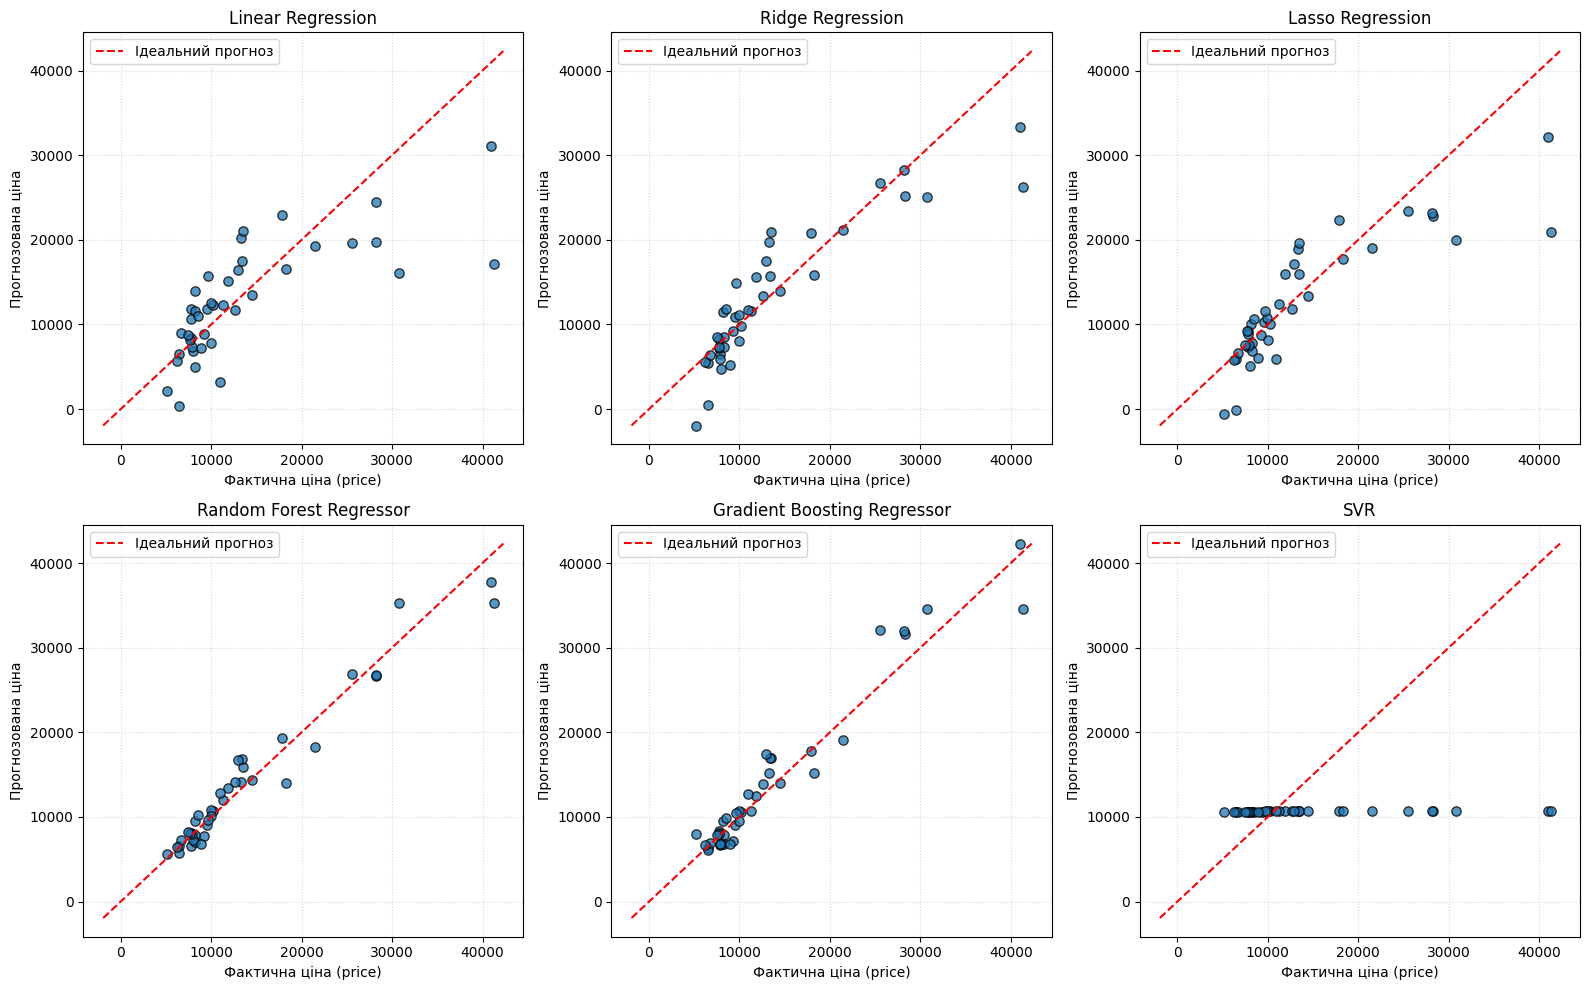

In [12]:
import math
import matplotlib.pyplot as plt
import numpy as np

n_models = len(pipelines)
n_cols = 3
n_rows = math.ceil(n_models / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 5 * n_rows))
axes = axes.flatten()

min_val = min(y_test.min(), min(p.predict(X_test).min() for p in pipelines.values()))
max_val = max(y_test.max(), max(p.predict(X_test).max() for p in pipelines.values()))

for i, (name, pipe) in enumerate(pipelines.items()):
  y_pred = pipe.predict(X_test)
  axes[i].scatter(y_test, y_pred, alpha=0.75, edgecolor="k", s=45)
  axes[i].plot([min_val, max_val], [min_val, max_val], "r--", linewidth=1.5, label="Ідеальний прогноз")
  axes[i].set_title(name)
  axes[i].set_xlabel("Фактична ціна (price)")
  axes[i].set_ylabel("Прогнозована ціна")
  axes[i].legend()
  axes[i].grid(True, linestyle=":", alpha=0.5)

for j in range(n_models, len(axes)):
  fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

## 14. Прогноз для 10 автомобілів

Випадково вибрати 10 автомобілів із тестової вибірки.

За допомогою моделі Random Forest отримати для них прогноз ціни та сформувати таблицю з такими даними:
- `car_ID`;
- фактична ціна;
- прогнозована ціна;
- абсолютна помилка;
- абсолютна відсоткова помилка.

Прокоментувати отримані результати.


In [13]:
import numpy as np
import pandas as pd

rf_pipe = pipelines["Random Forest Regressor"]
rf_preds_all = pd.Series(rf_pipe.predict(X_test), index=X_test.index)

sample_idx = X_test.sample(n=10, random_state=42).index

y_true_sample = y_test.loc[sample_idx]
y_pred_sample = rf_preds_all.loc[sample_idx]
abs_err = (y_true_sample - y_pred_sample).abs()
ape_pct = (abs_err / y_true_sample) * 100

forecast_10 = pd.DataFrame({
    "car_ID": car_id_test.loc[sample_idx].values,
    "Фактична ціна": y_true_sample.values,
    "Прогнозована ціна": y_pred_sample.values,
    "Абсолютна помилка": abs_err.values,
    "Абсолютна відсоткова помилка (%)": ape_pct.values,
})

print(forecast_10.to_string(index=False))

 car_ID  Фактична ціна  Прогнозована ціна  Абсолютна помилка  Абсолютна відсоткова помилка (%)
     26         6692.0           7298.805            606.805                          9.067618
    176         9988.0          10798.650            810.650                          8.116239
    148        10198.0          10714.570            516.570                          5.065405
     17        41315.0          35310.690           6004.310                         14.533003
     69        28248.0          26595.285           1652.715                          5.850733
    147         7463.0           8230.000            767.000                         10.277368
    144         9960.0          10065.200            105.200                          1.056225
     85        14489.0          14346.480            142.520                          0.983643
    195        12940.0          16765.650           3825.650                         29.564529
    160         7788.0           7995.560         

## 15. Висновки

Сформулювати підсумкові висновки за результатами роботи.

У висновках:
- порівняти якість усіх моделей;
- проаналізувати R², MAE, MSE і MAPE;
- зазначити, яка модель показала найкращі результати за отриманими метриками;
- прокоментувати величину похибок;
- звернути увагу на можливі ознаки перенавчання;
- коротко оцінити вплив попередньої обробки даних на результати моделювання.


Найкращою моделлю став Random Forest Regressor (R² = 0.9494, MAE = 1447.34, MSE = 3.997e+06, MAPE = 10.36%), трохи слабший результат показав Gradient Boosting Regressor (R² = 0.9291, MAE = 1703.69, MSE = 5.597e+06, MAPE = 12.64%). Обидва ансамблі суттєво випередили Ridge (R² = 0.7957, MAPE = 23.07%), Lasso (R² = 0.7061, MAPE = 22.61%), Linear Regression (R² = 0.5481, MAPE = 29.97%) і неналаштований SVR (R² = -0.0997, MAPE = 36.02%), що вказує на нелінійну природу ціни авто та велику чутливість квадратичної похибки MSE до відхилень.

На 10 випадкових авто з тесту Random Forest здебільшого дає малі похибки (наприклад, для car_ID 85 — 0.98%, car_ID 144 — 1.06%, car_ID 160 — 2.67%), але помиляється на дорогих чи нетипових машинах через усереднення в листках (car_ID 17 — абсолютна похибка 6004.31 при 14.53%, car_ID 195 — 29.56%).

Через малу вибірку (164 об'єкти у train) і багато ознак після One-Hot кодування без перевірки на train можливе перенавчання або погане узагальнення, що особливо видно по Linear Regression і SVR, тоді як регуляризація в Ridge та Lasso частково стабілізувала лінійні моделі.

Попередня обробка спрацювала ефективно: кліпінг за IQR зберіг дані, відбір за кореляцією зменшив дублювання ознак, а Yeo-Johnson разом із StandardScaler прибрав скошеність ключових змінних (enginesize з 0.9624 до 0.0448, horsepower з 0.8507 до 0.0663, curbweight з 0.7124 до 0.0499) у єдиному пайплайні без витоку даних.

## Загальні вимоги до виконання

- Не використовувати тестову вибірку для визначення меж викидів, кореляційного відбору ознак, навчання трансформерів, масштабування або кодування категорій.
- Усі параметри передобробки мають визначатися тільки за навчальною вибіркою.
- Фінальні метрики моделей обчислювати на тестовій вибірці.
- Не використовувати `car_ID` як предиктор.
- Не видаляти спостереження або ознаки без пояснення причини.
- До кожного основного етапу додати короткий змістовний висновок.
- У підсумкових висновках спиратися на отримані метрики та графіки.
